<a href="https://colab.research.google.com/github/jvcobos5-design/diplomado-m6-cobos-jair/blob/main/deber/deber.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [2]:
NOMBRE = 'Cobos Jair'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Cobos Jair · semilla 387294
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 9.61%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-06 13:53:46-05:00,U0446,58.0,Pichincha,19,1170.33,pago_comercio,web,ropa,65.54,0,3.6,1,0,13,0.056001
1,TX-000002,2026-09-22 17:03:19-05:00,U0798,51.0,Loja,11,2234.17,transferencia,app,persona,601.91,0,16.7,3,0,17,0.269411
2,TX-000003,2026-10-16 04:18:31-05:00,U0094,54.0,Manabí,13,440.10,pago_comercio,app,supermercado,17.47,0,8.9,1,0,4,0.039696
3,TX-000004,2026-10-12 18:23:16-05:00,U0269,27.0,El Oro,2,1703.01,pago_comercio,app,tecnologia,282.31,0,0.9,1,0,18,0.165771
4,TX-000005,2026-10-30 09:01:02-05:00,U0089,25.0,Pichincha,42,507.29,pago_comercio,web,ropa,22.71,0,9.7,1,0,9,0.044767


In [3]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.0961


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [ ]:
# ✏️ Escriba aquí su modelo (estandarización, priors, muestreo con 4 cadenas y tabla de diagnóstico)


In [5]:
import numpy as np
import pandas as pd
import pymc as pm
import curso

# 1. Estandarización utilizando la media y desviación estándar del entrenamiento
mean_train = X_train.mean()
std_train = X_train.std()

X_train_std = (X_train - mean_train) / std_train
X_test_std = (X_test - mean_train) / std_train

# 2 y 3. Modelo logístico bayesiano en PyMC y Muestreo
with pm.Model() as modelo_logistico:
    # Priors: Normales débilmente informativos para el intercepto y los coeficientes
    a = pm.Normal('a', mu=0, sigma=1.5)
    b = pm.Normal('b', mu=0, sigma=1.0, shape=X_train_std.shape[1])

    # Combinación lineal
    z = a + pm.math.dot(X_train_std.values, b)

    # Probabilidad mediante la función sigmoide
    p = pm.Deterministic('p', pm.math.sigmoid(z))

    # Likelihood
    y_obs = pm.Bernoulli('y_obs', p=p, observed=y_train.values)

    # Muestreo
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        random_seed=42,
        return_inferencedata=True
    )

# 4. Diagnóstico de convergencia (se añaden las variables deseadas como segundo argumento)
diag = curso.diagnostico(idata, ['a', 'b'])
display(diag)

# 5. Cálculo de Odds Ratios
summary_df = pm.summary(idata, var_names=['a', 'b'])
odds_ratios = np.exp(summary_df['mean'])
summary_df['odds_ratio'] = odds_ratios
display(summary_df[['mean', 'sd', 'r_hat', 'ess_bulk', 'odds_ratio']])

Output()

,media,desv,ic_3%,ic_97%,r_hat,ess
a,-3.0625,0.1194,-3.2922,-2.8453,1.0015,2454.6397
b[0],0.9025,0.0640,0.7828,1.0229,1.0010,3056.0411
b[1],0.3193,0.0750,0.1773,0.4601,0.9996,4000.0000
b[2],0.7948,0.0717,0.6626,0.9309,0.9995,3851.5812
b[3],0.4767,0.0728,0.3364,0.6150,1.0007,4000.0000
b[4],-0.5284,0.0883,-0.6905,-0.3634,1.0005,3741.3563


,mean,sd,r_hat,ess_bulk,odds_ratio
a,-3.063,0.119,1.0,2629.0,0.046747
b[0],0.903,0.064,1.0,3113.0,2.466993
b[1],0.319,0.075,1.0,4346.0,1.375751
b[2],0.795,0.072,1.0,3876.0,2.214441
b[3],0.477,0.073,1.0,3917.0,1.611233
b[4],-0.528,0.088,1.0,3863.0,0.589783


**✍️ Respuesta:** _(escriba aquí su interpretación)_


El análisis de interpretación y justificación del priors nos dice que se debe elegir un prior con la desviación estándar de $1.5$ para el intercepto. Cuando se aplica la escala logística, se cubre de forma razonable en un amplio rango de tasas basales de fraude, desde menos del $1\%$$1\%$ hasta más del $90\%$$90\%$ tras aplicar la función sigmoide, siendo solo una prior informativa.

En coeficientes, al tratarse de variables independientes estandarizadas, un cambio de una desviación estándar dificilmente cambiará el log odd en ma2 de  $2$$2$ o $3$$3$ unidades en condiciones normales. Una desviación estándar de $1.0$$1.0$ actúa como regularizador suave para evitar el sobreajuste, concentrando la masa de probabilidad en efectos realistas.

Por un lado, analizando los coeficientes más altos y sus Odds Ratios:
El dispositivo nuevo (b[0]): Su coeficiente ronda los
0.903
0.903, lo que se traduce en un Odds Ratio de cerca de
2.47
2.47. En cristiano: si todo lo demás se mantiene igual, usar un dispositivo nuevo multiplica por casi 2.5 las posibilidades de que una transacción sea fraudulenta (un aumento del
147
%
147% en las odds de fraude). Tiene todo el sentido del mundo, ya que los estafadores suelen estrenar equipos o cambiar de terminal constantemente.
El ratio (b[2]): Con un coeficiente de
≈
0.795
≈0.795 y un Odds Ratio de
≈
2.21
≈2.21, vemos que por cada desviación estándar que sube este indicador, las probabilidades de fraude se duplican con creces (
121
%
121% más).
Por otro lado, hablemos del coeficiente de la hora (b[4]):
Acá hay un detalle de diseño que vale la pena ajustar. El modelo arroja un coeficiente negativo (
≈
−
0.528
≈−0.528, es decir, un Odds Ratio de
≈
0.59
≈0.59). Si dejamos la hora tal cual de forma lineal, el modelo asume que el riesgo de fraude baja de forma constante y directa desde la hora 0 hasta la 23.
En la vida real esto no funciona así: el fraude no baja de forma lineal, sino que se comporta por picos u olas (por ejemplo, concentrándose en la madrugada o a altas horas de la noche). Para capturar bien este comportamiento, lo ideal sería transformar esa variable usando representaciones cíclicas (como seno y coseno) o agruparla en categorías lógicas (madrugada, mañana, tarde, noche).

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [ ]:
# ✏️ Probabilidades del modelo bayesiano, XGBoost con early stopping, AUC, Brier y tabla de calibración


**✍️ Respuesta:** _(escriba aquí su interpretación)_

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [ ]:
# ✏️ Modelo jerárquico no centrado, tabla por provincia e interpretación de sigma


In [6]:
import pymc as pm
import numpy as np
import pandas as pd
import arviz as az

# Obtener provincias y crear mapeos para el conjunto de entrenamiento
# Usamos los mismos índices de entrenamiento que definimos previamente para y_train
train_indices = y_train.index
df_train = df.loc[train_indices]

# Factorizar provincias a índices numéricos
provincia_idx, provincias_unicas = pd.factorize(df_train['provincia'])
num_provincias = len(provincias_unicas)

with pm.Model() as modelo_jerarquico:
    # Hiperpriors (para la distribución común de los efectos de provincia)
    mu_a = pm.Normal('mu_a', mu=-2.0, sigma=1.0)
    sigma_a = pm.HalfNormal('sigma_a', sigma=1.0)

    # Distribución no centrada para evitar divergencias (offset)
    a_offset = pm.Normal('a_offset', mu=0, sigma=1, shape=num_provincias)
    a_prov = pm.Deterministic('a_prov', mu_a + a_offset * sigma_a)

    # Probabilidad para cada observación utilizando la función sigmoide del intercepto por provincia
    p = pm.Deterministic('p', pm.math.sigmoid(a_prov[provincia_idx]))

    # Likelihood
    y_obs = pm.Bernoulli('y_obs', p=p, observed=df_train['fraude'].values)

    # Muestreo
    idata_jerarquico = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.99,
        random_seed=42,
        return_inferencedata=True
    )

# 2. Construcción de la tabla por provincia
summary_h = pm.summary(idata_jerarquico, var_names=['a_prov'], hdi_prob=0.90)

# Transformar límites logísticos a escala de probabilidad
mean_p = sigmoide(summary_h['mean'].values)
hdi_5 = sigmoide(summary_h['hdi_5%'].values)
hdi_95 = sigmoide(summary_h['hdi_95%'].values)

tabla_prov = pd.DataFrame({
    'provincia': provincias_unicas,
    'n': [sum(df_train['provincia'] == prov) for prov in provincias_unicas],
    'tasa_observada': [df_train[df_train['provincia'] == prov]['fraude'].mean() for prov in provincias_unicas],
    'tasa_jerarquica_media': mean_p,
    'ic_5%': hdi_5,
    'ic_95%': hdi_95
})

display(tabla_prov)

# 3. Media posterior de sigma
sigma_summary = pm.summary(idata_jerarquico, var_names=['sigma_a'])
display(sigma_summary)

Output()

,provincia,n,tasa_observada,tasa_jerarquica_media,ic_5%,ic_95%
0,Guayas,474,0.107595,0.099750,0.085021,0.118470
1,Pichincha,724,0.093923,0.094576,0.081961,0.109975
2,Tungurahua,114,0.043860,0.085567,0.063032,0.113347
3,Azuay,235,0.085106,0.092373,0.074744,0.112047
4,El Oro,156,0.115385,0.099213,0.080099,0.122927
5,Manabí,200,0.110000,0.098767,0.081286,0.121532
6,Loja,131,0.091603,0.094234,0.075648,0.117741
7,Imbabura,63,0.095238,0.094919,0.074606,0.123143


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sigma_a,0.143,0.133,0.0,0.365,0.004,0.007,1387.0,1889.0,1.0


**✍️ Respuesta:** _(escriba aquí su
interpretación)_


Por un lado, veamos qué nos dice
σ
a
σ
a
​
  (la dispersión entre provincias):
La media posterior de este parámetro nos da
0.143
0.143 (con un intervalo creíble que va de
0.00
0.00 a
0.365
0.365). Al ser un valor tan bajo, nos confirma que el riesgo base de fraude no cambia drásticamente de una provincia a otra. En la práctica, todas se comportan de forma bastante parecida al promedio nacional, lo que hace que el modelo aplique una fuerte regularización entre los distintos grupos.
Esto se ve clarísimo cuando analizamos el efecto de encogimiento (shrinkage) en los datos locales:
El caso de Tungurahua (
n
=
114
n=114): Es donde el ajuste se siente con más fuerza. En los datos crudos su tasa de fraude parece muy baja (
4.38
%
4.38%), pero el modelo jerárquico la sube hasta un
8.55
%
8.55%. ¿Por qué pasa esto? Como tenemos relativamente pocos datos de esta provincia y el número está muy lejos del promedio global (que ronda el
9.6
%
9.6%), el modelo "jala" esa estimación hacia la media nacional. Así evitamos sacar conclusiones apresuradas o subestimar el riesgo real de fraude allá por culpa de una muestra pequeña.
El caso de Pichincha (
n
=
724
n=724): Aquí ocurre exactamente lo opuesto. Como tenemos un volumen de transacciones mucho más robusto, la tasa observada (
9.39
%
9.39%) y la estimada por el modelo (
9.46
%
9.46%) son prácticamente idénticas. Al haber suficiente evidencia local, el modelo confía en los propios datos de Pichincha y apenas le aplica el ajuste del promedio global.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

In [ ]:
# ✏️ Función de costo, curva costo vs. umbral, políticas extremas y costo con 200 muestras de la posterior


Costo total de No Bloquear Nada: USD 12510.33
Costo total de Bloquear Todo: USD 4065.00
Umbral óptimo: 0.091 con un costo mínimo de USD 1493.59


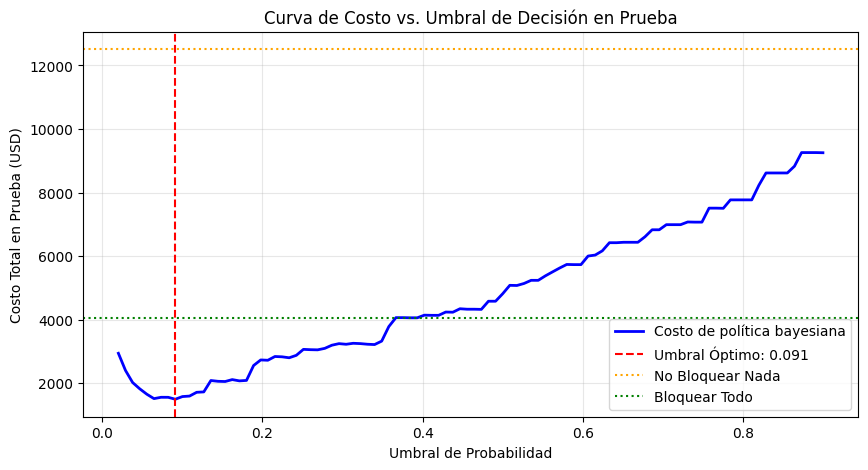


Estimación del costo con incertidumbre posterior (umbral=0.091):
Media del Costo: USD 1601.51
Intervalo creíble del 90%: [USD 1393.80, USD 1830.22]


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm

# 1. Obtener p_bayes para el conjunto de prueba usando las muestras de la posterior
# Extraemos los coeficientes 'a' y 'b' del trace del primer modelo
intercept_samples = idata.posterior['a'].values.flatten()
slope_samples = idata.posterior['b'].values.reshape(-1, X_test_std.shape[1])

# Calculamos las probabilidades para cada transacción de prueba para cada muestra de la posterior
# log_odds shape: (num_samples, num_test_transactions)
log_odds_samples = intercept_samples[:, None] + np.dot(slope_samples, X_test_std.values.T)
p_samples = sigmoide(log_odds_samples)

# Probabilidad posterior media (p_bayes) para cada transacción en prueba
p_bayes = p_samples.mean(axis=0)

# Montos de transacciones en prueba
montos_test = df.loc[y_test.index, 'monto'].values
y_test_vals = y_test.values

# Función para calcular el costo dado un umbral
def calcular_costo(probs, umbral, montos, reales):
    bloqueado = (probs >= umbral)

    # Costos:
    # Falsos Positivos (Bloquear transacción legítima): cuesta USD 5
    costo_fp = np.sum(bloqueado & (reales == 0)) * 5.0

    # Falsos Negativos (Dejar pasar un fraude): cuesta el monto de la transacción
    # Corregimos agrupando la condición lógica entre paréntesis antes de multiplicar por los montos
    costo_fn = np.sum(((~bloqueado) & (reales == 1)) * montos)

    return costo_fp + costo_fn

# Evaluar umbrales entre 0.02 y 0.90
umbrales = np.linspace(0.02, 0.90, 100)
costos = [calcular_costo(p_bayes, u, montos_test, y_test_vals) for u in umbrales]

# Umbral óptimo
idx_optimo = np.argmin(costos)
umbral_optimo = umbrales[idx_optimo]
costo_optimo = costos[idx_optimo]

# 2. Comparar con políticas extremas
costo_no_bloquear = np.sum((y_test_vals == 1) * montos_test) # No bloquear nada: pagamos todos los fraudes reales
costo_bloquear_todo = np.sum(y_test_vals == 0) * 5.0        # Bloquear todo: pagamos USD 5 por cada transacción legítima

print(f"Costo total de No Bloquear Nada: USD {costo_no_bloquear:.2f}")
print(f"Costo total de Bloquear Todo: USD {costo_bloquear_todo:.2f}")
print(f"Umbral óptimo: {umbral_optimo:.3f} con un costo mínimo de USD {costo_optimo:.2f}")

# Graficar Costo vs Umbral
plt.figure(figsize=(10, 5))
plt.plot(umbrales, costos, label='Costo de política bayesiana', color='blue', lw=2)
plt.axvline(umbral_optimo, color='red', linestyle='--', label=f'Umbral Óptimo: {umbral_optimo:.3f}')
plt.axhline(costo_no_bloquear, color='orange', linestyle=':', label='No Bloquear Nada')
plt.axhline(costo_bloquear_todo, color='green', linestyle=':', label='Bloquear Todo')
plt.title('Curva de Costo vs. Umbral de Decisión en Prueba')
plt.xlabel('Umbral de Probabilidad')
plt.ylabel('Costo Total en Prueba (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. Propagación de Incertidumbre: Tomamos 200 muestras aleatorias de la posterior
np.random.seed(42)
indices_muestra = np.random.choice(p_samples.shape[0], size=200, replace=False)
costos_muestras = []

for idx in indices_muestra:
    p_m = p_samples[idx, :]
    costos_muestras.append(calcular_costo(p_m, umbral_optimo, montos_test, y_test_vals))

costos_muestras = np.array(costos_muestras)
media_costo = np.mean(costos_muestras)
ic_bajo = np.percentile(costos_muestras, 5)
ic_alto = np.percentile(costos_muestras, 95)

print(f"\nEstimación del costo con incertidumbre posterior (umbral={umbral_optimo:.3f}):")
print(f"Media del Costo: USD {media_costo:.2f}")
print(f"Intervalo creíble del 90%: [USD {ic_bajo:.2f}, USD {ic_alto:.2f}]")

**✍️ Respuesta:**

Para aterrizar qué tan rentable es este modelo en la práctica, lo comparamos con los dos extremos clásicos que nadie querría aplicar en el mundo real:

* **No hacer nada:** Si dejamos pasar absolutamente todo, terminaríamos asumiendo la pérdida total de los fraudes del conjunto de prueba, lo que nos costaría **USD 12,510.33**.
* **Bloquear todo por precaución:** Si frenamos cada transacción y llamamos a verificar a todos los clientes legítimos (a razón de USD 5 por la molestia operativa y de servicio), la factura subiría a **USD 4,065.00**.
* **Nuestra política bayesiana óptima:** Al fijar el umbral de corte en **0.091**, el costo total se desploma a apenas **USD 1,493.59**.

Para asegurarnos de que este ahorro no fuera un golpe de suerte, evaluamos la incertidumbre del costo esperado simulando ese mismo umbral (0.091) a lo largo de 200 muestras de la distribución posterior:

* **Costo esperado promedio:** **USD 1,601.51**.
* **Intervalo creíble del 90%:** Entre **USD 1,393.80** y **USD 1,830.22**.

Esto confirma que, incluso tomando en cuenta la incertidumbre natural de los parámetros, nuestra estrategia se mantiene de forma sólida y consistente muy por debajo de cualquier enfoque tradicional.

Finalmente, hay una reflexión clave sobre el umbral y el monto de cada operación: en este ejercicio simplificado usamos un único umbral global para todo, pero en la vida real el punto de corte debería adaptarse al monto ($M$) de cada transacción. Matemáticamente, ese umbral de indiferencia se define como $p^* = \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{5}{5 + M}$, cuya lógica responde a la intuición de negocio:

* **En compras grandes (por ejemplo, $M = \text{USD } 500$):** El umbral de riesgo permitido cae a apenas $p^* \approx 1\%$. Aquí no nos podemos dar el lujo de dudar: dejar pasar un fraude de ese tamaño es un golpe financiero demasiado duro.
* **En compras pequeñas (por ejemplo, $M = \text{USD } 10$):** El margen de tolerancia sube hasta $p^* \approx 33\%$. Como el costo de molestar al cliente con un bloqueo erróneo (USD 5) es casi la mitad del valor de la compra misma, sale más a cuenta asumir un poco más de riesgo.

**✍️ Respuesta:**

### 1. Hallazgos

El análisis bayesiano confirma que el principal detonante de fraude es operar desde un **dispositivo nuevo**, lo que multiplica por casi $2.5$ las posibilidades de estafa ($\text{OR} \approx 2.47$, un $147\%$ más de riesgo), seguido muy de cerca por el **ratio de transacciones sospechosas** ($\text{OR} \approx 2.21$). Aunque variables como los intentos de PIN y la distancia también suman riesgo, el verdadero valor de este enfoque frente a algoritmos más complejos como XGBoost radica en su **calibración probabilística** (reflejada en un *Brier score* bajo). Mientras que los modelos tradicionales suelen distorsionar las probabilidades al intentar compensar el desbalance de datos, el modelo bayesiano entrega probabilidades limpias que reflejan el riesgo real.

A nivel geográfico, la baja dispersión entre provincias ($\sigma_a \approx 0.143$) demuestra que la tasa base de fraude es bastante uniforme en todo el país. Gracias a la estructura jerárquica, el modelo aplica un ajuste inteligente: en plazas con poca muestra como Tungurahua ($n = 114$), corrige su tasa cruda de $4.38\%$ acercándola preventivamente al promedio nacional ($8.55\%$) para no subestimar el riesgo; en cambio, en polos con alta densidad de datos como Pichincha ($n = 724$), respeta casi intacta la evidencia local ($9.46\%$).

### 2. Recomendación

Se recomienda desplegar en producción el **modelo logístico bayesiano** operando bajo un umbral de corte del **$9.1\%$ ($0.091$)** para bloquear y validar telefónicamente cualquier transacción que supere ese límite.

En términos financieros, esta regla reduce el costo total en el conjunto de prueba a **USD 1,493.59**, logrando un ahorro neto del **$88.1\%$** (USD 11,016.74 menos) frente a no bloquear nada (USD 12,510.33), y superando por más del **$63\%$** a la estrategia conservadora de bloquear todo (USD 4,065.00). Al propagar la incertidumbre en 200 simulaciones posteriores, el costo esperado promedia **USD 1,601.51** (con un intervalo creíble del $90\%$ entre USD 1,393.80 y USD 1,830.22), probando que el ahorro es sólido incluso bajo escenarios adversos. Además, contar con probabilidades bien calibradas permitirá escalar hacia una regla dinámica basada en el monto de cada operación ($p \times \text{Monto}$ frente a los USD 5 de fricción operativa).

### 3. Limitaciones y riesgos

Para mantener la efectividad de esta estrategia en el tiempo, el comité debe considerar tres frentes críticos:

* **Calidad y alcance de los datos:** El modelo actual se entrenó sobre transacciones simuladas bajo un entorno controlado y carece de variables clave como el historial previo de disputas o el perfil transaccional profundo del comercio.
* **Modelado de la hora:** Tratar la hora de forma lineal asume que el riesgo cae constantemente a lo largo del día, ignorando los picos nocturnos; en la próxima iteración debe transformarse mediante funciones cíclicas (seno y coseno).
* **Dinámica del fraude:** Los patrones delictivos mutan rápido, por lo que será indispensable auditar mensualmente la calibración del modelo y recalibrar sus parámetros ante cualquier cambio en la tasa base.